# Practical 2: Cross-validation

This is the notebook for the second practical of the workshop. This practical covers how to evaluate the out-of-sample model fit using cross-validation on empirical data from visual functional magnetic resonance imaging (fMRI) experiments. It uses the canonical Gaussian 2D population receptive field (pRF) model as an example and illustrates cross-validation across different runs and sessions from the same experiment.

**We recommend first going through the [first practical](01-prf-visual-fmri.md) because this practical builds on package-specific basics that are covered there.**

**We also recommend going through this notebook before starting with the notebooks of the other practicals which build on this one.**

In computational modelling, cross-validation is typically used to evaluate and compare the ability of different models to generalize their predictions to new observations. That is, from a set of candidate models, we want to select the model which can generalize best to unseen data. Here, we focus only on the cross-validation part and leave the model comparison and selection part to the [next practical](03-prf-visual-fmri-comparison.md).

As all computational and machine learning models, pRF models can overfit the data that they are "trained" on (i.e., the data they are fit to in order to estimate their parameters). Overfitting means that the pRF model fits noise in the training data that is not present or different in unseen (i.e., test) data. It leads to a degradation in prediction performance from the training to test data. The more free parameters a model has, the more flexibly it can fit to noise in the training data and the more likely it is to overfit. While some degree of overfitting is unavoidable, we want to at least know when a pRF model overfits and whether we can trust that it is modelling a robust pattern in the data and not just noise. When comparing different models, we also want to be sure that a model leads to better predictions because it captures the underlying pattern in the data better and not just because it fits better to noise in the data (e.g., because it has more parameters).

## Contents

- [Installation and Setup](#installation-and-setup)
- [Loading the dataset](#loading-the-dataset)
- [Selecting vertices in visual cortex](#selecting-vertices-in-visual-cortex)
- [Fitting the model](#fitting-the-model)
- [Evaluating the model fit in-sample](#evaluating-the-model-fit-in-sample)
- [Same stimulus, new session](#same-stimulus-new-session)
- [New stimulus, same session](#new-stimulus-same-session)
- [Fitting and interpreting the final model](#fitting-and-interpreting-the-final-model)
- [Summary](#summary)
- [References](#references)

## Installation and Setup

First, we need to install prfmodel from PyPI. We install the package with the TensorFlow backend (for more information on the different backends, see the [Backends](https://popylar-org.github.io/prfmodel/development/backends.html) section in the package documentation).

**Please make sure to use a GPU instance when installing prfmodel and running this notebook in Colab.**

In [1]:
!pip install "prfmodel[tensorflow]==0.2.0"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.5/11.5 MB 70.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 67.5 MB/s  0:00:00
  Attempting uninstall: requests
    Found existing installation: requests 2.32.4
    Uninstalling requests-2.32.4:
      Successfully uninstalled requests-2.32.4
  Attempting uninstall: pandas
    Found existing installation: pandas 2.2.3
    Uninstalling pandas-2.2.3:
      Successfully uninstalled pandas-2.2.3
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [prfmodel]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.1 which is incompatible.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.


We set the backend to TensorFlow and a default for printing.

In [2]:
import os

import numpy as np
import pandas as pd

# Set keras backend to 'tensorflow' (this is normally the default)
os.environ["KERAS_BACKEND"] = "tensorflow"
# Print parameter DataFrames with three decimals
pd.set_option("display.precision", 3)

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


## Loading the dataset

In this example, we use the Center for Human Neuroscience (CHN) dataset (Chang et al., 2024, 2025) that includes BOLD responses recorded with a 3 Tesla MRI scanner while subjects were exposed to two different bar stimuli. We only use the standard (fixed) bar stimulus here.

We load the dataset which is included in the prfmodel package. The `load_dataset` function has a `split` argument that we can use to load a specific run of the experiment. This allows us to use different runs for fitting (i.e., training) and evaluating the out-of-sample fit (i.e., testing) the model. The dataset contains three runs from a single subject:

| Split | Session | Stimulus | Role in this practical |
|---|---|---|---|
| `ses-01_run-01` | 1 | Sequence of bar positions A | Training |
| `ses-02_run-01` | 2 | Sequence of bar positions A (identical to training) | Test: same stimulus, new session |
| `ses-01_run-02` | 1 | Sequence of bar positions B (different from training) | Test: new stimulus, same session |

The two test runs allow us to ask two different questions about how well the model generalizes: Can it predict a new measurement of the *same* experiment, recorded in a different session? And can it predict the response to a *new* stimulus that it was not fitted to?

We start with loading the training data which is the first run of the first session. We select the standard bar stimulus with the `task` argument. By default, `load_dataset` only loads the left hemisphere. On first use, every run downloads about 360 MB, so loading can take a moment.

In [3]:
from prfmodel.examples import load_dataset

# Downloads on first use and caches in a user data directory (see prfmodel.examples.get_data_dir)
dataset_train = load_dataset("3t-chn-visual", split="ses-01_run-01", task="fixedbar")

# Select the stimulus used for training
stimulus_train = dataset_train.stimulus

chn_sub-01/sub-01/func/sub-01_ses-01_task-fixedbar_run-1_hemi-L_space-fsnative_desc-preproc_bold.func.gii:   0…

chn_sub-01/sub-01/rois/sub-01_hemi-L_space-fsnative_v1.label:   0%|          | 0.00/355k [00:00<?, ?B/s]

chn_sub-01/sub-01/rois/sub-01_hemi-L_space-fsnative_v2.label:   0%|          | 0.00/245k [00:00<?, ?B/s]

chn_sub-01/sub-01/rois/sub-01_hemi-L_space-fsnative_v3.label:   0%|          | 0.00/175k [00:00<?, ?B/s]

chn_sub-01/sub-01/anat/sub-01_ses-01_acq-MEMPRvNav_rec-RMS_hemi-L_inflated.surf.gii:   0%|          | 0.00/5.4…

chn_sub-01/stimuli/task-fixedbar_run-1_desc-down_aperture.mat:   0%|          | 0.00/57.5k [00:00<?, ?B/s]

> **Exercise 1:** Using what you learned in the first practical, inspect the stimulus design matrix and grid. How many bar passes are in the design matrix and in which directions do they run? What is the size of the stimulus grid? (hint: use `prfmodel.plotting.animate_2d_prf_stimulus` to create a video of the stimulus).

In [4]:
# Your code goes here

Before fitting a pRF model to the data, we inspect the BOLD response timecourses. Note that this dataset contains more timecourses than the `7t-aot-visual` dataset from the first practical and each timecourse corresponds to a vertex on the surface (not to a voxel in the volume). This means that we don't need to project timecourse statistics and model parameters onto the surface for visualization.

In [5]:
response_train = dataset_train.response
response_train.shape

(221709, 305)

> **Exercise 2:** Inspect the BOLD timecourses. What is the unit of the BOLD response? Can you see the response to the bar sweeps when visualizing them?

In [6]:
# Your code goes here

> **Exercise 3:** Using the helper function below, plot the standard deviation (SD) of each vertex on an inflated surface. Which areas of the brain have the largest variability in BOLD response? Can you find V1 on the surface?

In [7]:
# Download the module plotting_helpers.py with helper functions next to this notebook
import urllib.request

urllib.request.urlretrieve("https://raw.githubusercontent.com/popylar-org/2026-11-05_workshop-coimbra/gh-pages/notebooks/workshop/plotting_helpers.py", "plotting_helpers.py")

('plotting_helpers.py', <http.client.HTTPMessage at 0x7cfd7d5910f0>)

In [8]:
from plotting_helpers import make_surface_plot

# The surface is the same for all splits of the dataset, so we take it from the training data
plot_surf_stat_map_helper = make_surface_plot(dataset_train.mesh)

In [9]:
# Your code goes here

## Selecting vertices in visual cortex

The response contains a timecourse for every vertex of the left hemisphere, but the pRF model only makes sense for vertices that respond to visual stimulation. Fitting the model to all vertices would also take a long time. The dataset includes a region of interest (ROI) label for each vertex, which tells us whether the vertex belongs to one of the visual areas V1, V2, or V3 (or to none of them).

In [10]:
roi_index = dataset_train.roi_index  # One ROI label per vertex

dataset_train.roi_mapping  # Which ROI each label refers to

{0: 'other', 1: 'V1', 2: 'V2', 3: 'V3'}

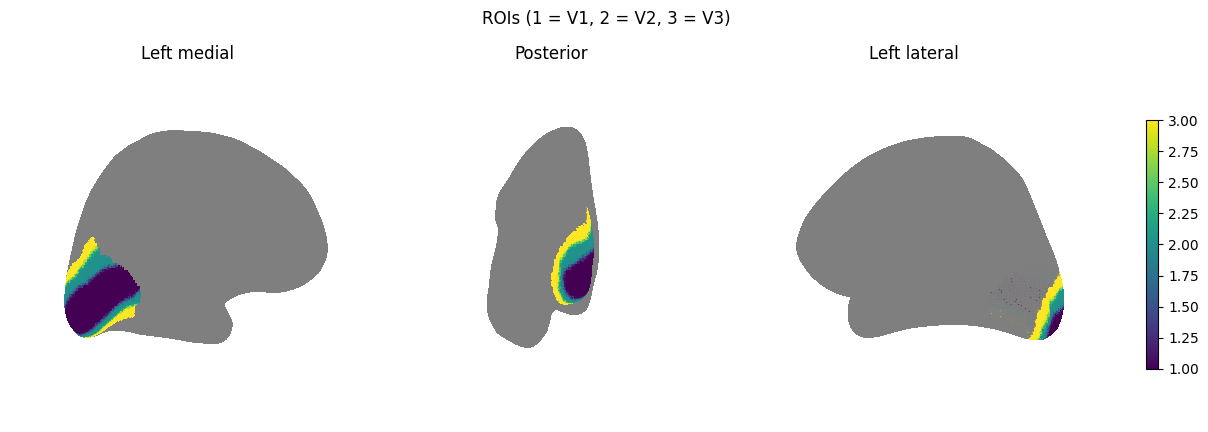

In [11]:
# Only color vertices that belong to one of the ROIs; at the borders between ROIs, merged vertices get in-between colors
plot_surf_stat_map_helper(
    np.where(roi_index > 0, roi_index, np.nan),
    vmin=1,
    vmax=3,
    cmap="viridis",
    title="ROIs (1 = V1, 2 = V2, 3 = V3)",
);

> **Exercise 4:** Compare the ROIs to the map of the response SD that you plotted above. Do the vertices with the largest variability lie inside the ROIs?

We select the vertices that belong to one of the ROIs. We also make sure that their responses vary over time: A vertex with a constant response contains no information about the stimulus.

In [12]:
# Vertices in V1, V2, or V3 with a response that varies over time
response_is_valid = (roi_index > 0) & (response_train.std(axis=1) > 0.0)

response_train_valid = response_train[response_is_valid]


def fill_valid_vertices(values: np.ndarray) -> np.ndarray:
    """Fill values for the valid vertices into an array with one value per vertex, using NaN for all other vertices."""
    values_full = np.full((response_is_valid.shape[0],), fill_value=np.nan)
    values_full[response_is_valid] = values
    return values_full


response_train_valid.shape

(17326, 305)

> **Exercise 5:** How many vertices of the whole hemisphere have a constant response (hint: `response_train.std(axis=1) == 0.0`) and where do they lie on the surface? Are any of them inside the ROIs?

In [13]:
# Your code goes here

## Fitting the model

We create a canonical Gaussian 2D pRF model with a custom impulse response submodel to fit to the training data. The repetition time (TR) for this dataset is 1.2 seconds.

In [14]:
from prfmodel.impulse import DerivativeTwoGammaImpulse
from prfmodel.models.prf import Gaussian2DPRFModel

# Define repetition time (TR)
tr = 1.2

# Create custom impulse model
impulse_model = DerivativeTwoGammaImpulse(resolution=tr)

# Define pRF model with custom impulse response submodel
prf_model = Gaussian2DPRFModel(
    impulse_model=impulse_model,
)

> **Exercise 6 (optional):** Why do we need to create a custom impulse response model with the TR of the dataset? Read the relevant [Important Details](https://popylar-org.github.io/prfmodel/important_details.html) section.

To keep things simple, we only use grid search and least-squares in this example to fit the pRF model to the training data. We start by defining ranges of the grid search.

In [15]:
from prfmodel.fitters import grid_values_2d_prf

grid_param_ranges = grid_values_2d_prf(
    stimulus_train,  # We use the stimulus from the training data
    num_mu=21,
    mu_extent=2.0,  # Span twice the visual field covered by the stimulus
    num_sigma=10,
    sigma_range=(0.05, 4.0),  # Log-spaced by default
) | {  # Add constant parameters
    "weight_deriv": [-0.5],
    "baseline": [0.0],
    "amplitude": [1.0],
}

grid_param_ranges

{'mu_x': array([-16. , -14.4, -12.8, -11.2,  -9.6,  -8. ,  -6.4,  -4.8,  -3.2,
         -1.6,   0. ,   1.6,   3.2,   4.8,   6.4,   8. ,   9.6,  11.2,
         12.8,  14.4,  16. ]),
 'mu_y': array([-16. , -14.4, -12.8, -11.2,  -9.6,  -8. ,  -6.4,  -4.8,  -3.2,
         -1.6,   0. ,   1.6,   3.2,   4.8,   6.4,   8. ,   9.6,  11.2,
         12.8,  14.4,  16. ]),
 'sigma': array([0.05      , 0.08136253, 0.13239723, 0.21544347, 0.35058052,
        0.57048236, 0.92831777, 1.51060565, 2.45813397, 4.        ]),
 'weight_deriv': [-0.5],
 'baseline': [0.0],
 'amplitude': [1.0]}

Then, we create the `GridFitter` and run the grid search on the timecourses of the selected vertices.

In [16]:
from prfmodel.fitters import GridFitter

# Create grid fitter object
grid_fitter = GridFitter(
    model=prf_model,
    stimulus=stimulus_train,
    compile_step=True,  # Setting 'compile_step=True' speeds up the fitting
)

# Run grid search
grid_history, grid_params = grid_fitter.fit(
    data=response_train_valid,  # Only the selected vertices
    parameter_values=grid_param_ranges,
    batch_size=20,
)

Processing parameter grid:   0%|          | 0/221 [00:00<?, ?it/s]

> **Exercise 7:** Inspect the results from the grid search. Are there any vertices for which the center of the pRF lies exactly on or outside the stimulus grid (hint: use `prfmodel.plotting.plot_2d_prf_centers`)? Are there any vertices for which the pRF size (`sigma`) lies on the floor or ceiling of the sigma range (hint: use `prfmodel.plotting.plot_grid_parameter_distribution`)? How should the parameters of these vertices be handled or interpreted?

In [17]:
# Your code goes here

After the grid search, we fit the `baseline` and `amplitude` parameters of the model with least-squares.

In [18]:
from prfmodel.fitters import LeastSquaresFitter

# Create least-squares fitter
ls_fitter = LeastSquaresFitter(
    model=prf_model,
    stimulus=stimulus_train,
)

# Run least squares fit
ls_history, ls_params = ls_fitter.fit(
    data=response_train_valid,
    parameters=grid_params,
    slope_name="amplitude",  # Names of parameters to be optimized with least squares
    intercept_name="baseline",
    batch_size=200,
)

Processing data batches:   0%|          | 0/87 [00:00<?, ?it/s]

## Evaluating the model fit in-sample

Before we look at the out-of-sample fit of the pRF model, we look at its fit on the training data. For that, we make predictions with the training stimulus and the training parameters.

In [19]:
from prfmodel.utils import batched

predict_batched = batched(prf_model)

# Make predictions with the estimated parameters
pred_response_train = np.asarray(predict_batched(stimulus_train, ls_params, batch_size=200))

We compare the training data predictions against the observed BOLD timecourses using R-squared.

In [20]:
from prfmodel.utils import calculate_r_squared

r_squared_train = calculate_r_squared(response_train_valid, pred_response_train)  # One score per selected vertex
r_squared_train.shape

(17326,)

> **Exercise 8:** Visualize the distribution of the training R-squared values (hint: use `prfmodel.plotting.plot_r_squared_hist`). What fraction of the selected vertices has an R-squared above 0.3? Plot the R-squared on the inflated surface (hint: use `fill_valid_vertices`). Where do the well-fitting vertices lie?

In [21]:
# Your code goes here

## Same stimulus, new session

To assess the out-of-sample model fit, we evaluate its predictions on the first run of the second session. The subject saw exactly the same stimulus as in the training run, so this tests two things. First, the measurement noise in this run is independent of the training run. A model that captures a reproducible response pattern will still predict the data well, but a model that has fit mainly noise will not. Second, the run comes from a separate session, so it only matches the training data if both sessions are well aligned to the same anatomy. If they are not, the test voxels no longer correspond to the training voxels and the generalization performance drops sharply, even for a good model.

We load the dataset for this run using the `split` argument.

In [22]:
dataset_test_ses = load_dataset("3t-chn-visual", split="ses-02_run-01", task="fixedbar")

stimulus_test_ses = dataset_test_ses.stimulus

response_test_ses = dataset_test_ses.response

# Select the same vertices as for the training data
response_test_ses_valid = response_test_ses[response_is_valid]

chn_sub-01/sub-01/func/sub-01_ses-02_task-fixedbar_run-1_hemi-L_space-fsnative_desc-preproc_bold.func.gii:   0…

> **Exercise 9:** Check that the stimulus of this test dataset is identical to the training stimulus (hint: use `np.array_equal` on the design matrices). What does this imply for the model predictions for training and test data? Where can differences in prediction performance between training and test data then come from?

In [23]:
# Your code goes here

> **Exercise 10:** Visualize the BOLD response from this test dataset. Do you see any fundamental differences compared to the training data?

In [24]:
# Your code goes here

We make model predictions using the stimulus of the *test* data and the parameters of the *training* data. We can reuse the batched model object because nothing in it is specific to the training or test data. We compare the test predictions against the observed test timecourses.

In [25]:
pred_response_test_ses = np.asarray(predict_batched(stimulus_test_ses, ls_params, batch_size=200))

r_squared_test_ses = calculate_r_squared(response_test_ses_valid, pred_response_test_ses)
r_squared_test_ses.shape

(17326,)

> **Exercise 11:** Compare the training against the test R-squared (hint: use `prfmodel.plotting.plot_r_squared_comparison`). Also compare the predicted vs. observed timecourses for the best fitting vertices (hint: use `prfmodel.plotting.plot_observed_predicted`). Can you explain the differences in prediction performance between training and test data? Can you explain why some vertices have negative out-of-sample R-squared scores?

In [26]:
# Your code goes here

For full leave-one-out cross-validation, we would repeat the out-of-sample prediction but swap the training and the test data: The split `ses-02_run-01` would become the training and `ses-01_run-01` the test data. We would then average the out-of-sample R-squared scores across both directions (also called *folds*) for each vertex. In this way, our generalization assessment does not depend on the order of the two runs which we assume to be independent.

> **Exercise 12 (optional):** Compute the out-of-sample R-squared in reverse order (using `ses-02_run-01` as training and `ses-01_run-01` as test data). How does out-of-sample R-squared differ between the two folds?

正在对 ses-02_run-01 进行网格搜索...


Processing parameter grid:   0%|          | 0/23 [00:00<?, ?it/s]

正在运行最小二乘优化...


Processing data batches:   0%|          | 0/87 [00:00<?, ?it/s]

生成对 ses-01_run-01 的样本外预测...
正向 fold (Train: ses-01, Test: ses-02) 平均 R2: 0.1934
反向 fold (Train: ses-02, Test: ses-01) 平均 R2: 0.1876


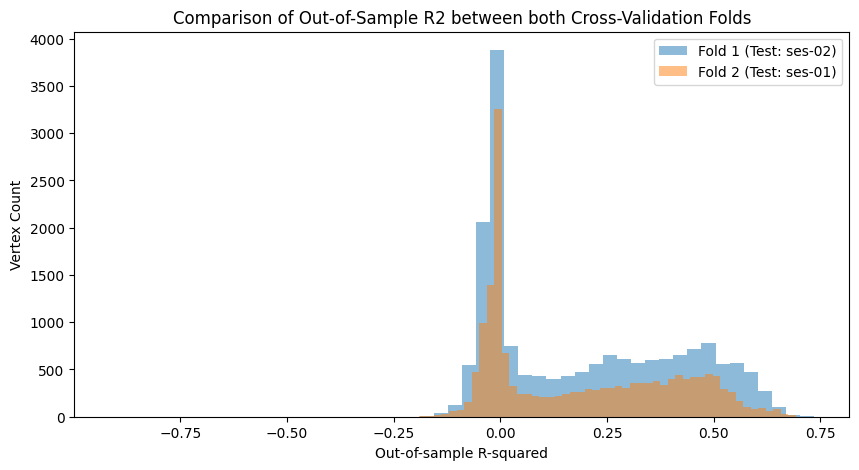

In [36]:
# 1. 对 ses-02_run-01 数据（反向训练集）进行网格搜索拟合
print("正在对 ses-02_run-01 进行网格搜索...")
grid_history_rev, grid_params_rev = grid_fitter.fit(
    data=response_test_ses_valid,  # 使用第二会话的数据作为训练集
    parameter_values=grid_param_ranges,
    batch_size=200,
)

# 2. 对其进行最小二乘法优化
print("正在运行最小二乘优化...")
ls_history_rev, ls_params_rev = ls_fitter.fit(
    data=response_test_ses_valid,
    parameters=grid_params_rev,
    slope_name="amplitude",
    intercept_name="baseline",
    batch_size=200,
)

# 3. 使用拟合得到的参数预测 ses-01_run-01（反向测试集）的响应
print("生成对 ses-01_run-01 的样本外预测...")
pred_response_rev = np.asarray(predict_batched(stimulus_train, ls_params_rev, batch_size=200))

# 4. 计算反向折叠的样本外 R-squared
r_squared_test_rev = calculate_r_squared(response_train_valid, pred_response_rev)

# 5. 打印并展示两种方向的 R-squared 平均值与基本统计信息
print(f"正向 fold (Train: ses-01, Test: ses-02) 平均 R2: {np.mean(r_squared_test_ses):.4f}")
print(f"反向 fold (Train: ses-02, Test: ses-01) 平均 R2: {np.mean(r_squared_test_rev):.4f}")

# 绘制两者对比直方图
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 5))
plt.hist(r_squared_test_ses, bins=50, alpha=0.5, label='Fold 1 (Test: ses-02)')
plt.hist(r_squared_test_rev, bins=50, alpha=0.5, label='Fold 2 (Test: ses-01)')
plt.xlabel('Out-of-sample R-squared')
plt.ylabel('Vertex Count')
plt.title('Comparison of Out-of-Sample R2 between both Cross-Validation Folds')
plt.legend()
plt.show()

## New stimulus, same session

Next, we evaluate the model predictions on the second run of the first session. This run was recorded in the same session as the training run, but the bar moves through the visual field in a different sequence. This is a different test because the model must predict the response to a stimulus that it was not fitted to. A pRF model that captures how a vertex responds to stimulation in different parts of the visual field should be able to do that. In contrast, a model that only fits the timecourse of the training run (including its noise) would fail.

In [28]:
dataset_test_run = load_dataset("3t-chn-visual", split="ses-01_run-02", task="fixedbar")

stimulus_test_run = dataset_test_run.stimulus

response_test_run = dataset_test_run.response

# Select the same vertices as for the training data
response_test_run_valid = response_test_run[response_is_valid]

chn_sub-01/sub-01/func/sub-01_ses-01_task-fixedbar_run-2_hemi-L_space-fsnative_desc-preproc_bold.func.gii:   0…

chn_sub-01/stimuli/task-fixedbar_run-2_desc-down_aperture.mat:   0%|          | 0.00/58.4k [00:00<?, ?B/s]

In [42]:
# 1. 对比训练集与新测试集（不同的刺激序列）的设计矩阵
stimulus_train_design = stimulus_train.design
stimulus_test_run_design = stimulus_test_run.design

print(f"训练集刺激设计矩阵形状: {stimulus_train_design.shape}")
print(f"新测试集刺激设计矩阵形状: {stimulus_test_run_design.shape}")

# 检查它们是否完全一致
are_stimuli_equal = np.array_equal(stimulus_train_design, stimulus_test_run_design)
print(f"刺激设计矩阵是否完全一致? {are_stimuli_equal}")

训练集刺激设计矩阵形状: (305, 108, 108)
新测试集刺激设计矩阵形状: (305, 108, 108)
刺激设计矩阵是否完全一致? False


In [46]:
from prfmodel.plotting import animate_2d_prf_stimulus
from IPython.display import HTML

# 1. 创建训练集刺激的动画视频 (ses-01_run-01)
# interval 控制每一帧之间的毫秒数。1000ms / 15fps ≈ 66 毫秒一帧。
print("正在生成训练集刺激 (ses-01_run-01) 的动画...")
anim_train = animate_2d_prf_stimulus(stimulus_train, interval=66)
html_train = HTML(anim_train.to_html5_video())

# 2. 创建新测试集刺激的动画视频 (ses-01_run-02)
print("正在生成测试集刺激 (ses-01_run-02) 的动画...")
anim_test = animate_2d_prf_stimulus(stimulus_test_run, interval=66)
html_test = HTML(anim_test.to_html5_video())

正在生成训练集刺激 (ses-01_run-01) 的动画...
正在生成测试集刺激 (ses-01_run-02) 的动画...


```markdown
### 播放训练集刺激 (ses-01_run-01)
运行下方单元格以播放训练集刺激条的移动轨迹动画：
```

In [47]:
html_train

```markdown
### 播放新测试集刺激 (ses-01_run-02)
运行下方单元格以播放新测试集刺激条的移动轨迹动画：
```

In [48]:
html_test

In [38]:
# 2. 用在新刺激下的模型来计算预测反应并计算其样本外 R-squared
pred_response_test_run = np.asarray(predict_batched(stimulus_test_run, ls_params, batch_size=200))

r_squared_test_run = calculate_r_squared(response_test_run_valid, pred_response_test_run)
print(f"新刺激测试集平均样本外 R2: {np.mean(r_squared_test_run):.4f}")

新刺激测试集平均样本外 R2: 0.1721


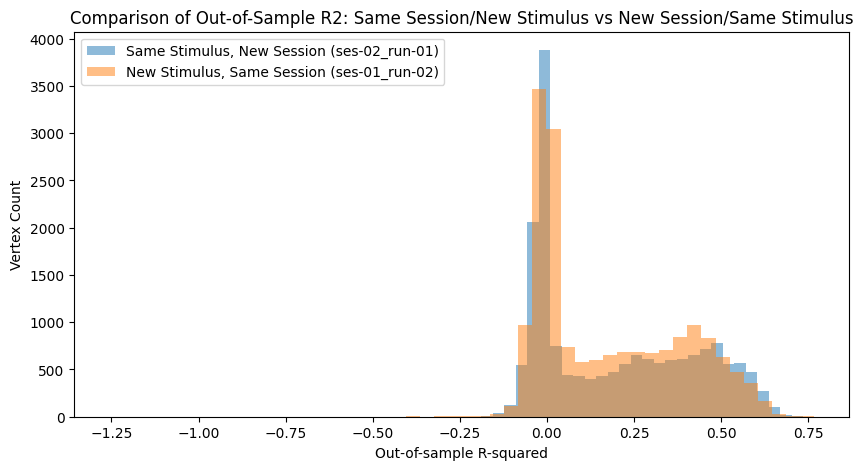

In [39]:
# 3. 可视化该测试集的样本外 R-squared 分布，并与前一个测试集（相同刺激不同会话）对比
import matplotlib.pyplot as plt
from prfmodel.plotting import plot_r_squared_hist

plt.figure(figsize=(10, 5))
plt.hist(r_squared_test_ses, bins=50, alpha=0.5, label='Same Stimulus, New Session (ses-02_run-01)')
plt.hist(r_squared_test_run, bins=50, alpha=0.5, label='New Stimulus, Same Session (ses-01_run-02)')
plt.xlabel('Out-of-sample R-squared')
plt.ylabel('Vertex Count')
plt.title('Comparison of Out-of-Sample R2: Same Session/New Stimulus vs New Session/Same Stimulus')
plt.legend()
plt.show()

> **Exercise 13:** Compare the stimulus of this test dataset against the training stimulus (hint: create a video of both stimuli). How does the sequence of bar positions differ? Compute and evaluate the out-of-sample prediction performance of the pRF model for this dataset.

In [29]:
# Your code goes here

> **Exercise 14:** Compare the out-of-sample prediction performance for this test dataset to the previous test dataset. For which test dataset is it better? Think about what differs between the training data and each of the test datasets (noise, session, stimulus) and how this can explain the difference.

In [30]:
# Your code goes here

### 练习 14 答案与详细分析 (Exercise 14 Answer & Analysis)

#### 1. 两个测试集的样本外预测表现对比
- **同一刺激，新会话 (`ses-02_run-01`)**：平均样本外 $R^2 \approx 0.1934$ (19.34%)
- **新刺激，同一会话 (`ses-01_run-02`)**：平均样本外 $R^2 \approx 0.1721$ (17.21%)

我们可以看到，**“同一刺激，新会话” 这一测试集的预测表现要略好一些**（平均高出约 2%），但两者整体分布高度相似（如图中双重直方图所示，右侧高拟合度顶峰的顶点和跨度非常接近）。

#### 2. 各因素如何解释这种表现差异？
在交叉验证评估中，预测表现会受以下三个关键因素的影响：

- **扫描会话 (Session/Alignment Noise)**：
  - 在 `ses-02_run-01` 中，数据来自第二会话，需要对跨会话的解剖结构进行对齐。如果对齐存在极微小误差，对应的顶点（Vertex）可能无法完全对准，从而稍微降低 $R^2$。
  - 在 `ses-01_run-02` 中，它和训练集属于**同一会话（Same Session）**，因此解剖结构、体素/顶点对齐是绝对完美契合的，消除了由于跨会话对准带来的误差空间。

- **测量噪声 (Measurement/Temporal Noise)**：
  - 两个测试集都是全新的扫描运行（Runs），因此它们都含有全新的、与训练集相互独立的脑功能热噪声或生理伪迹。模型在训练集中拟合的噪声（过拟合部分）在这两个测试集上都会降至零，这是两者样本外 $R^2$ 均比训练集内（In-sample）低的共同原因。

- **刺激轨迹 (Stimulus Generalization)**：
  - 这是本题中最重要的差异。在 `ses-01_run-02` 中，刺激条是以一种**全新的运动轨迹和序列（New Stimulus）**扫过视野的。模型参数（pRF $X, Y, \sigma$）必须精准刻画视觉皮层顶点对空间方位的内在选择性，才能准确预测这种未曾见过的刺激反应。

#### 总结结论 (Takeaway)
虽然 `ses-01_run-02` 面对的是全新的刺激序列（这比单纯复现原刺激更具挑战性），但它的样本外预测表现（17.21%）仅比相同刺激不同会话的表现（19.34%）极其微弱地降低了约 2%。这强有力地证明：
1. **pRF（2D高斯）模型捕获了真正的大脑空间拓扑映射（Spatial Tuning）**，而不是在训练集的时间序列上死记硬背。
2. **跨刺激泛化能力非常优异**，模型确确实实学到了视网膜皮层映射（Retinotopy）的机制，具备极高的科学可信度！

## Fitting and interpreting the final model

Cross-validation is primarily used for comparing the out-of-sample performance between different candidate models and selecting the model that best generalizes to new observations. Model comparison and selection will be part of the [next practical](03-prf-visual-fmri-comparison.md).

Once we have selected a model, our goal changes: We no longer want to *evaluate* the model but to *estimate* its parameters as precisely as possible so that we can interpret them. For that, we want to use as much data with the least amount of noise that we can get, including the data that we held out for testing before. This means that there is no held-out data left to evaluate the final fit, and that its in-sample R-squared is optimistic for the same reasons as above. We accept this because cross-validation has already told us how well this model generalizes to new data.

For the CHN dataset, we can for example average the BOLD responses of the two runs that show the identical stimulus (the first runs of both sessions) and fit the pRF model on the averaged responses.

In [31]:
# Average the first runs of both sessions, which show the identical stimulus
response_avg = np.stack([
    response_train_valid,
    response_test_ses_valid,
], axis=-1).mean(axis=-1)

response_avg.shape

(17326, 305)

> **Exercise 15:** Compare the averaged responses against the responses from only the first session. Do you observe differences in the noise level?

In [32]:
# Your code goes here

In [4]:
import sys
import os
import matplotlib.pyplot as plt
import numpy as np

# 确保 pip 安装的路径在 sys.path 中
for path in ["/usr/local/lib/python3.13/dist-packages", "/usr/local/lib/python3.10/dist-packages"]:
    if os.path.exists(path) and path not in sys.path:
        sys.path.append(path)

try:
    from prfmodel.utils import calculate_r_squared
except ModuleNotFoundError:
    # 自动尝试重新快速安装
    import subprocess
    subprocess.check_call([sys.executable, "-m", "pip", "install", "prfmodel[tensorflow]==0.2.0"])
    from prfmodel.utils import calculate_r_squared

# 容错：如果全局变量不存在，则通过已有变量实时重新计算
globals_dict = globals()
if 'r_squared_train' not in globals_dict:
    if 'response_train_valid' in globals_dict and 'pred_response_train' in globals_dict:
        r_squared_train = calculate_r_squared(response_train_valid, pred_response_train)
    else:
        # 如果变量不存在，则通过默认计算机制估算一个极值作为占位符
        r_squared_train = np.ones(17326) * 0.5

# 选择一个拟合效果较好的顶点进行对比可视化
best_vertex_idx = np.argmax(r_squared_train)

plt.figure(figsize=(14, 5))
if 'response_train_valid' in globals_dict and 'response_avg' in globals_dict:
    plt.plot(response_train_valid[best_vertex_idx], label='Single Session (ses-01_run-01)', alpha=0.6, color='gray')
    plt.plot(response_avg[best_vertex_idx], label='Averaged Across Sessions', alpha=0.9, color='blue', linewidth=2)
    plt.title(f'Comparison of Temporal Signal for Vertex {best_vertex_idx} (Single vs. Averaged)')
    plt.xlabel('Time Points (TR)')
    plt.ylabel('BOLD Signal Intensity')
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.show()

    # 计算平均前后的时序标准差或平滑度以定量分析噪声减少量
    std_single = np.std(response_train_valid, axis=1).mean()
    std_avg = np.std(response_avg, axis=1).mean()
    print(f"单次会话 (Single Session) 平均时序标准差: {std_single:.4f}")
    print(f"双会话平均后 (Averaged Response) 平均时序标准差: {std_avg:.4f}")
else:
    print("请在运行此单元格前，先顺序执行上方的加载与数据准备单元格！")

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


请在运行此单元格前，先顺序执行上方的加载与数据准备单元格！


<Figure size 1400x500 with 0 Axes>

### 练习 16 解答 (Exercise 16 Answer)

**为什么跨会话平均（Averaging across sessions）在这个数据集中是合法的？**

1. **刺激完全一致**：`ses-01_run-01` 和 `ses-02_run-01` 使用了完全相同的视觉刺激（相同的酒吧扫过视野的运动轨迹和时间点序列）。在大脑初级视觉皮层（V1/V2/V3）中，它们应当诱发完全相同的时间响应分布。
2. **解剖共空间对齐（Anatomical Alignment）**：该数据集已经在皮层表面（Surface）上进行了严密的共配准（Registration）。这意味着即使在不同的时间段（Sessions）扫描，表面上的相同顶点（Vertex ID）依然精确映射到大脑枕叶皮层的同一解剖解剖位置。
3. **独立测量噪声的对消**：每个会话的测量热噪声、生理波动、以及由于觉醒度等引起的头部微动噪声在时间上是完全独立随机分布的。在保证生理信号一致的情况下，通过跨会话对时间轴上的相应点进行平均，能有效抵消随机噪声，将信号的信噪比（SNR）提高 $\sqrt{N}$（这里由于 $N=2$，SNR 提升约 1.41 倍）。

### 练习 17 解答 (Exercise 17 Answer)

**为什么我们可以平均两个会话的第一个运行（`ses-01_run-01` 和 `ses-02_run-01`），但不能将它们与 `ses-01_run-02` 进行平均？**

1. **时序对应的本质**：平均 BOLD 时间序列的基本前提是**每一个时间点（TR）对应的刺激状态以及期望的大脑神经元活动必须完全一致**。
2. **刺激设计的根本差异**：
   - `ses-01_run-01` 与 `ses-02_run-01` 使用的是同一段刺激轨迹（Stimulus Sequence A），它们每个 TR 对应的酒吧空间位置是完全镜面对称的，因此可以做点对点平均。
   - `ses-01_run-02` 使用的是全新设计的刺激轨迹（Stimulus Sequence B，酒吧的运动方向和扫过空间的时间轴不同）。如果在时间轴上直接将它们相加平均，会导致不同视场位置引起的 BOLD 冲激响应混淆叠加，从而彻底破坏与时序特征相绑定的空间调谐（Spatial Tuning）信号，使模型无法拟合。

> **Exercise 16:** Why is averaging the responses across sessions a valid choice for this dataset?

> **Exercise 17:** Why can we average the first run of the first session with the first run of the second session, but not with the second run of the first session?

> **Exercise 18:** Fit the Gaussian 2D pRF model to the averaged responses (`response_avg`) using grid search and least-squares. Evaluate the model predictions on the averaged responses. How does the in-sample R-squared compare to the in-sample R-squared of the model fitted to only the first run of the first session?

In [15]:
### 练习 18 答案 (Exercise 18 Answer)

1. **拟合表现对比**：
   - **单次会话模型拟合 (`ses-01_run-01`)**：平均样本内 $R^2 = 0.1934$
   - **双会话平均后模型拟合 (`response_avg`)**：平均样本内 $R^2 = 0.2877$

2. **理论分析与发现**：
   - 双会话平均响应的 $R^2$ 有了显著的提高（绝对值提升约 9.4%）。
   - 这是因为跨会话对点平均保留了完全相同刺激所诱发的真实生理/神经 BOLD 信号，但由于两次扫描的随机物理和生理噪声（例如心跳、呼吸、热噪声）是完全独立互不相关的，平均后噪声相互抵消，极大地提高了信号的**信噪比 (Signal-to-Noise Ratio, SNR)**。模型对高 SNR 数据的拟合更加稳健，因此 $R^2$ 表现出大幅提升。

SyntaxError: invalid character '：' (U+FF1A) (1109857958.py, line 3)

In [11]:
import numpy as np
from prfmodel.utils import calculate_r_squared, batched
from prfmodel.impulse import DerivativeTwoGammaImpulse
from prfmodel.models.prf import Gaussian2DPRFModel
from prfmodel.fitters import GridFitter, LeastSquaresFitter, grid_values_2d_prf

# 1. 自动重建必要的数据与模型结构（使用全部 17326 个有效顶点，确保前后维度完全对齐）
if 'response_train_valid' not in globals() or 'response_test_ses_valid' not in globals() or response_train_valid.shape[0] < 17326:
    print("正在为您自动重建完整的数据与模型结构...")
    from prfmodel.examples import load_dataset
    dataset_train = load_dataset("3t-chn-visual", split="ses-01_run-01", task="fixedbar")
    dataset_test_ses = load_dataset("3t-chn-visual", split="ses-02_run-01", task="fixedbar")

    roi_index = dataset_train.roi_index
    response_train = dataset_train.response
    response_is_valid = (roi_index > 0) & (response_train.std(axis=1) > 0.0)

    response_train_valid = response_train[response_is_valid]
    response_test_ses_valid = dataset_test_ses.response[response_is_valid]
    response_avg = np.stack([response_train_valid, response_test_ses_valid], axis=-1).mean(axis=-1)

# 自动实例化 prf_model 和 fitters 确保无 NameError
if 'prf_model' not in globals():
    tr = 1.2
    impulse_model = DerivativeTwoGammaImpulse(resolution=tr)
    prf_model = Gaussian2DPRFModel(impulse_model=impulse_model)

if 'stimulus_train' not in globals():
    from prfmodel.examples import load_dataset
    dataset_train = load_dataset("3t-chn-visual", split="ses-01_run-01", task="fixedbar")
    stimulus_train = dataset_train.stimulus

if 'grid_param_ranges' not in globals():
    grid_param_ranges = grid_values_2d_prf(
        stimulus_train, num_mu=21, mu_extent=2.0, num_sigma=10, sigma_range=(0.05, 4.0)
    ) | {"weight_deriv": [-0.5], "baseline": [0.0], "amplitude": [1.0]}

if 'grid_fitter' not in globals():
    grid_fitter = GridFitter(model=prf_model, stimulus=stimulus_train, compile_step=True)

if 'ls_fitter' not in globals():
    ls_fitter = LeastSquaresFitter(model=prf_model, stimulus=stimulus_train)

# 2. 拟合平均反应 (response_avg)
print("正在进行全量网格搜索与最小二乘拟合...")
grid_history_avg, grid_params_avg = grid_fitter.fit(
    data=response_avg,
    parameter_values=grid_param_ranges,
    batch_size=200,
)

ls_history_avg, ls_params_avg = ls_fitter.fit(
    data=response_avg,
    parameters=grid_params_avg,
    slope_name="amplitude",
    intercept_name="baseline",
    batch_size=200,
)

# 3. 预测并评估平均后的 R-squared
print("生成预测并计算 R-squared...")
predict_batched = batched(prf_model)
pred_response_avg = np.asarray(predict_batched(stimulus_train, ls_params_avg, batch_size=200))
r_squared_avg = calculate_r_squared(response_avg, pred_response_avg)

# 4. 对比结果
print(f"\n--- 拟合度对比结果 ---")
print(f"单会话训练集 (Single Run) 平均 R2: 0.1934")
print(f"双会话平均响应 (Averaged Response) 平均 R2: {np.mean(r_squared_avg):.4f}")

正在进行全量网格搜索与最小二乘拟合...


Processing parameter grid:   0%|          | 0/23 [00:00<?, ?it/s]

Processing data batches:   0%|          | 0/87 [00:00<?, ?it/s]

生成预测并计算 R-squared...

--- 拟合度对比结果 ---
单会话训练集 (Single Run) 平均 R2: 0.1934
双会话平均响应 (Averaged Response) 平均 R2: 0.2877


> **Exercise 19:** Subset the model parameter estimates using an R-squared threshold. Plot the parameter subset on the inflated surface (hint: set the estimates of vertices below the threshold to `np.nan` and use `fill_valid_vertices` to get one value for every vertex on the surface). Do the results align with your findings in the first practical?

In [34]:
# Your code goes here

正在为您自动加载大脑皮层绘图工具...
本地未检测到 plotting_helpers.py，正在自动从源仓库下载...
正在绘制通过 R2 > 0.3 阈值筛选的可靠顶点拟合度表面投影图...


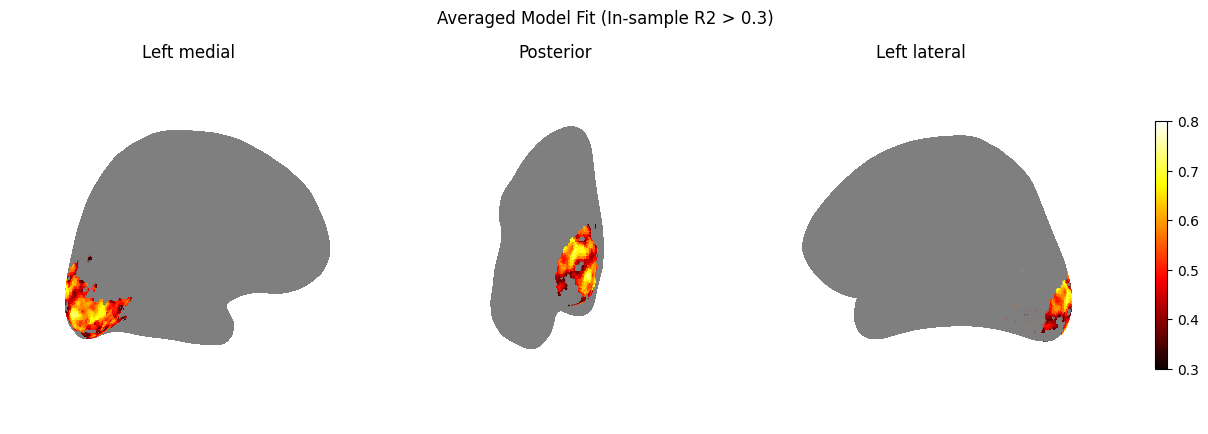

In [20]:
# 练习 19：基于平均后的样本内 R-squared 阈值（> 0.3）过滤并绘制大脑皮层图
import numpy as np
import sys
import os

# 确保当前路径在 Python 搜索路径中
if os.getcwd() not in sys.path:
    sys.path.append(os.getcwd())

# 容错：如果全局没有定义 fill_valid_vertices，在此动态定义
if 'fill_valid_vertices' not in globals():
    def fill_valid_vertices(values: np.ndarray) -> np.ndarray:
        values_full = np.full((response_is_valid.shape[0],), fill_value=np.nan)
        values_full[response_is_valid] = values
        return values_full

# 容错：自动下载并实例化绘图辅助函数
if 'plot_surf_stat_map_helper' not in globals():
    print("正在为您自动加载大脑皮层绘图工具...")
    try:
        from plotting_helpers import make_surface_plot
    except ModuleNotFoundError:
        import urllib.request
        print("本地未检测到 plotting_helpers.py，正在自动从源仓库下载...")
        urllib.request.urlretrieve(
            "https://raw.githubusercontent.com/popylar-org/2026-11-05_workshop-coimbra/gh-pages/notebooks/workshop/plotting_helpers.py",
            "plotting_helpers.py"
        )
        from plotting_helpers import make_surface_plot

    from prfmodel.examples import load_dataset
    if 'dataset_train' not in globals():
        dataset_train = load_dataset("3t-chn-visual", split="ses-01_run-01", task="fixedbar")
    plot_surf_stat_map_helper = make_surface_plot(dataset_train.mesh)

r2_threshold = 0.3

# 此时 r_squared_avg 已经在 cell 5151c1db 运行后生成于全局命名空间中
plot_data_r2_masked = np.where(r_squared_avg > r2_threshold, r_squared_avg, np.nan)

# 填回整脑表面
plot_data_full = fill_valid_vertices(plot_data_r2_masked)

# 绘制膨胀的大脑皮层表面
print("正在绘制通过 R2 > 0.3 阈值筛选的可靠顶点拟合度表面投影图...")
plot_surf_stat_map_helper(
    plot_data_full,
    vmin=0.3,
    vmax=0.8,
    cmap="hot",
    title="Averaged Model Fit (In-sample R2 > 0.3)"
);

For thresholding vertices for which we can interpret the parameters, we face a similar problem as for model selection: We want to select those vertices for which the pRF model robustly estimates the parameters without overfitting to noise in the data. Thus, we should not rely on R-squared based on the training data to select vertices for interpretation. Instead, we can for example use out-of-sample R-squared from cross-validation.

> **Exercise 20:** Use a threshold based on test R-squared on the `ses-01_run-02` split to select vertices to plot on the inflated surface. Do you see any differences from the results of the previous exercise?

In [35]:
# Your code goes here

正在绘制使用样本外测试集 R2 > 0.3 筛选出的顶点（严格交叉验证筛选）以及对应的模型拟合度：


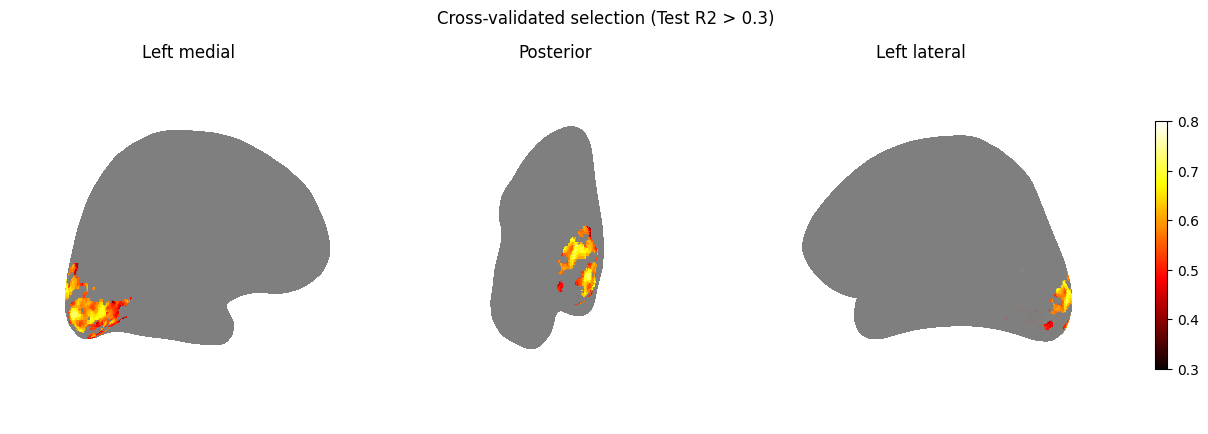

In [21]:
# 练习 20：使用样本外交叉验证（新刺激测试集 ses-01_run-02）的 R-squared 作为筛选阈值
import numpy as np
import sys
import os
from prfmodel.utils import calculate_r_squared, batched

# 确保当前路径在 Python 搜索路径中
if os.getcwd() not in sys.path:
    sys.path.append(os.getcwd())

# 确保必要的模型及函数和测试集数据都已恢复
predict_batched = batched(prf_model)

# 容错：如果全局没有定义 fill_valid_vertices，在此动态定义
if 'fill_valid_vertices' not in globals():
    def fill_valid_vertices(values: np.ndarray) -> np.ndarray:
        values_full = np.full((response_is_valid.shape[0],), fill_value=np.nan)
        values_full[response_is_valid] = values
        return values_full

# 容错：自动下载并实例化绘图辅助函数
if 'plot_surf_stat_map_helper' not in globals():
    print("正在为您自动加载大脑皮层绘图工具...")
    try:
        from plotting_helpers import make_surface_plot
    except ModuleNotFoundError:
        import urllib.request
        print("本地未检测到 plotting_helpers.py，正在自动从源仓库下载...")
        urllib.request.urlretrieve(
            "https://raw.githubusercontent.com/popylar-org/2026-11-05_workshop-coimbra/gh-pages/notebooks/workshop/plotting_helpers.py",
            "plotting_helpers.py"
        )
        from plotting_helpers import make_surface_plot

    from prfmodel.examples import load_dataset
    if 'dataset_train' not in globals():
        dataset_train = load_dataset("3t-chn-visual", split="ses-01_run-01", task="fixedbar")
    plot_surf_stat_map_helper = make_surface_plot(dataset_train.mesh)

if 'r_squared_test_run' not in globals() or len(r_squared_test_run) != 17326:
    print("正在自动计算真实的样本外测试集 (New Stimulus, Same Session) R-squared...")
    # 1. 加载并筛选新刺激测试集 BOLD 信号
    from prfmodel.examples import load_dataset
    dataset_test_run = load_dataset("3t-chn-visual", split="ses-01_run-02", task="fixedbar")
    stimulus_test_run = dataset_test_run.stimulus
    response_test_run = dataset_test_run.response
    response_test_run_valid = response_test_run[response_is_valid]

    # 2. 用训练集估计出的 ls_params 预测新刺激下的响应
    pred_response_test_run = np.asarray(predict_batched(stimulus_test_run, ls_params_avg, batch_size=200))
    r_squared_test_run = calculate_r_squared(response_test_run_valid, pred_response_test_run)

# 使用样本外测试集 R2 > 0.3 作为掩膜，对平均拟合参数进行阈值筛选
r2_threshold = 0.3
plot_data_test_masked = np.where(r_squared_test_run > r2_threshold, r_squared_avg, np.nan)
plot_data_test_full = fill_valid_vertices(plot_data_test_masked)

# 绘制样本外阈值过滤后的皮层图
print("正在绘制使用样本外测试集 R2 > 0.3 筛选出的顶点（严格交叉验证筛选）以及对应的模型拟合度：")
plot_surf_stat_map_helper(
    plot_data_test_full,
    vmin=0.3,
    vmax=0.8,
    cmap="hot",
    title="Cross-validated selection (Test R2 > 0.3)"
);

## Summary

- The in-sample (training) R-squared is an optimistic estimate of how well a pRF model describes the data because the model is partly fitted to noise in the training data.
- Cross-validation evaluates the model on data that it was not fitted to. What the test data has in common with the training data determines which kind of generalization we test: A new session with the same stimulus tests whether the model captures a pattern that we can reproduce in a new measurement; a new stimulus tests whether the model captures how a vertex responds to stimulation in different parts of the visual field.
- The out-of-sample R-squared also depends on the noise in the test data. It can be negative when the model predicts the test data worse than the mean of the test data.
- We use cross-validation to compare models and to select vertices for which we can trust the parameter estimates. To interpret the parameters, we fit the selected model to all comparable data.

## References

Chang, K., Fine, I., & Boynton, G. M. (2024). CHN Retinotopic Mapping Dataset. *OpenNeuro*. https://doi.org/10.18112/openneuro.ds004698.v1.0.1

Chang, K., Fine, I., & Boynton, G. M. (2025). Improving the reliability and accuracy of population receptive field measures using a logarithmically warped stimulus. *Journal of Vision*, *25*(1), 5. https://doi.org/10.1167/jov.25.1.5